# Introduction & Data Analysis

## Questions
1) Wrong dates - in excel End date = 42845.81041
2) Wrong duration calculation - some observations where total time < charging time and seems to be calculated wrong (should we fix or remove)
3) time zones - convert to 1 time zone ?, start and end date in different time zones.


In [173]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


In [174]:
df = pd.read_csv("datasets/EVChargingStationUsage.csv")
df.head(2)

,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,...,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284.0,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,...,-122.160309,USD,0.0,Customer,4,94301.0,4169.0,NaN,NaN,NaN


### Columns description (to be deleted in the final report)
* Station Name - Name of the station (47 stations)
* MAC Address - mac of the charging device (83 unique values)
* Org Name - organization (only 1 unique name - City of Palo Alto)
* Start Date - datetime of plugin (to be converted to datetime)
* Start Time Zone - time zone of the start date (3 unique values)
* End Date - datetime of plug out (to be converted to datetime)
* End Time Zone - time zone of the end date (3 unique values)
* Transaction Date - date of transaction in pacific time 
* Total duration - total duration of the vehicle being plugged in
* Charing time - duration of the actual charging 

(Can create new columns : Idle = Total time - charging time)

* Energy (kWh) 
* GHG Savings - estimated saving in gas emissions
* Gasoline Savings - estimated savings in gasoline

* Port type - Level 1 (slower charging), Level2 (faster charging) or missing 
* Port Number - port number in the charging station (1 or 2)
* Plug Type - 2 different plug types

* EVSE ID - Electric Vehicle Supply Equipment, ID of the charging equipment (has missng values)

* Address columns describing the station location
* User details

* Currency, Fee 

* Ended by - different reasons of ending the charging session

### Check for missing values and datatypes

In [175]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 259415 entries, 0 to 259414
Data columns (total 33 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Station Name                     259415 non-null  str    
 1   MAC Address                      259415 non-null  str    
 2   Org Name                         259415 non-null  str    
 3   Start Date                       259415 non-null  str    
 4   Start Time Zone                  259415 non-null  str    
 5   End Date                         259415 non-null  str    
 6   End Time Zone                    259415 non-null  str    
 7   Transaction Date (Pacific Time)  259206 non-null  str    
 8   Total Duration (hh:mm:ss)        259415 non-null  str    
 9   Charging Time (hh:mm:ss)         259415 non-null  str    
 10  Energy (kWh)                     259415 non-null  float64
 11  GHG Savings (kg)                 259415 non-null  float64
 12  Gasoline Savi

In [176]:
missing = df.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))

County                             84665
EVSE ID                            78948
System S/N                         78948
Model Number                       78948
Driver Postal Code                  8402
User ID                             7677
Currency                            1788
Ended By                             248
Transaction Date (Pacific Time)      209
Port Type                              9
dtype: int64


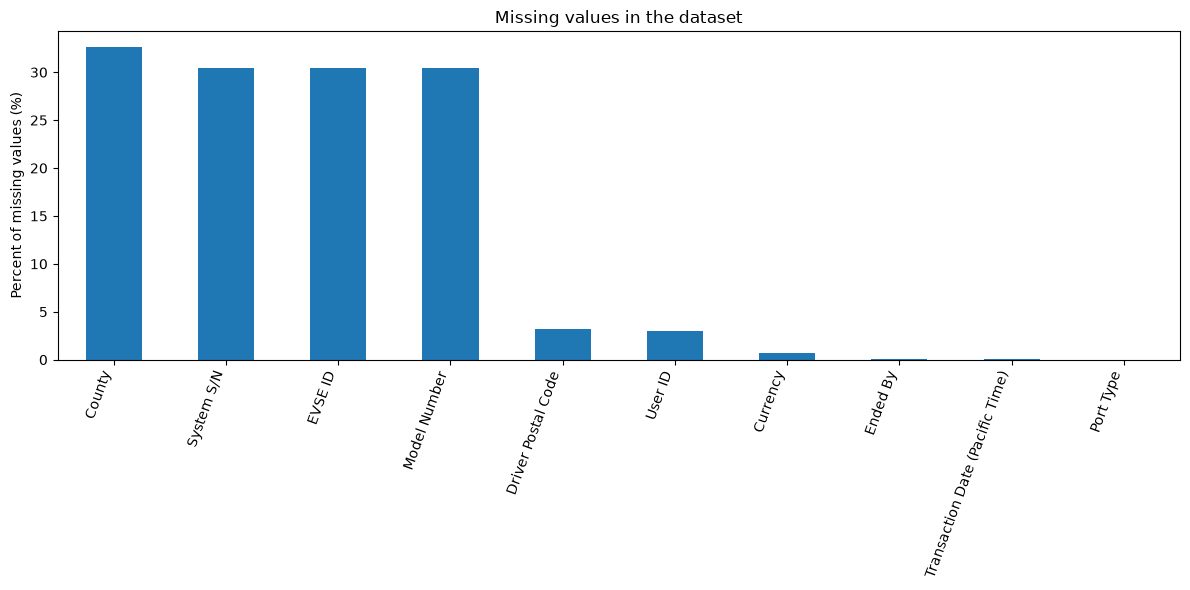

In [177]:
missing = (
    df.isna()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

missing = missing[missing > 0]
plt.figure(figsize=(12, 6))
missing.plot(kind="bar")
plt.ylabel("Percent of missing values (%)")
plt.title("Missing values in the dataset")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()

### Datetime columns and durations

In [178]:
unique_timezones = df['Start Time Zone'].unique()
print('Unique time zones in the dataset:', unique_timezones)
print('Number of rows where start date zone is different from end date zone:', (df['Start Time Zone'] != df['End Time Zone']).sum())

Unique time zones in the dataset: <StringArray>
['PDT', 'PST', 'UTC']
Length: 3, dtype: str
Number of rows where start date zone is different from end date zone: 120


In [179]:
# convert date columns to datetime format
df['Start Date'] = pd.to_datetime(df['Start Date'], errors = 'coerce')
df['End Date'] = pd.to_datetime(df['End Date'], errors = 'coerce')
df['Transaction Date (Pacific Time)'] = pd.to_datetime(df['Transaction Date (Pacific Time)'], errors='coerce')
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 259415 entries, 0 to 259414
Data columns (total 33 columns):
 #   Column                           Non-Null Count   Dtype         
---  ------                           --------------   -----         
 0   Station Name                     259415 non-null  str           
 1   MAC Address                      259415 non-null  str           
 2   Org Name                         259415 non-null  str           
 3   Start Date                       259415 non-null  datetime64[us]
 4   Start Time Zone                  259415 non-null  str           
 5   End Date                         259375 non-null  datetime64[us]
 6   End Time Zone                    259415 non-null  str           
 7   Transaction Date (Pacific Time)  259166 non-null  datetime64[us]
 8   Total Duration (hh:mm:ss)        259415 non-null  str           
 9   Charging Time (hh:mm:ss)         259415 non-null  str           
 10  Energy (kWh)                     259415 non-null  float

In [180]:
# extract hours and seconds from duration columns
df["total_duration_sec"] = pd.to_timedelta(df["Total Duration (hh:mm:ss)"], errors="coerce").dt.total_seconds()
df['charging_duration_sec'] = pd.to_timedelta(df["Charging Time (hh:mm:ss)"], errors="coerce").dt.total_seconds()

df['total_duration_hours'] = df['total_duration_sec'] / 3600
df['charging_duration_hours'] = df['charging_duration_sec'] / 3600

#Add new column representing the idle time 
df["idle_seconds"] = df["total_duration_sec"] - df["charging_duration_sec"]
df['idle_hours'] = df['idle_seconds'] / 3600

# adding new column with etracted hour and categorized time of day
df["start_hour"] = df["Start Date"].dt.hour
conditions = [
    df["start_hour"].between(0, 5),
    df["start_hour"].between(6, 11),
    df["start_hour"].between(12, 17),
    df["start_hour"].between(18, 23)
]

labels = ["Night", "Morning", "Afternoon", "Evening"]

df["time_of_day"] = np.select(
    conditions,
    labels,
    default=None
)



In [181]:
df[df['total_duration_sec']<df['charging_duration_sec']].head(5)


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,System S/N,Model Number,total_duration_sec,charging_duration_sec,total_duration_hours,charging_duration_hours,idle_seconds,idle_hours,start_hour,time_of_day
1184,PALO ALTO CA / HIGH #4,000D6F0000A20F47,City of Palo Alto,2011-12-21 08:44:00,PST,2011-12-21 11:33:00,PST,2011-12-21 11:33:00,2:48:34,2:49:42,...,NaN,NaN,10114.0,10182.0,2.809444,2.828333,-68.0,-0.018889,8,Morning
6311,PALO ALTO CA / BRYANT #2,000D6F0000A2108E,City of Palo Alto,2012-10-22 09:09:00,PDT,2012-10-26 09:44:00,PDT,2012-10-26 09:44:00,0:34:30,3:52:36,...,NaN,NaN,2070.0,13956.0,0.575000,3.876667,-11886.0,-3.301667,9,Morning
8017,PALO ALTO CA / HIGH #4,000D6F0000A20F47,City of Palo Alto,2013-01-07 15:01:00,PST,2013-01-07 17:05:00,PST,2013-01-07 17:05:00,2:03:48,2:03:51,...,NaN,NaN,7428.0,7431.0,2.063333,2.064167,-3.0,-0.000833,15,Afternoon
8090,PALO ALTO CA / BRYANT #2,000D6F0000A2108E,City of Palo Alto,2013-01-10 09:51:00,PST,2013-01-11 10:23:00,PST,2013-01-11 10:23:00,0:31:03,5:33:11,...,NaN,NaN,1863.0,19991.0,0.517500,5.553056,-18128.0,-5.035556,9,Morning
8957,PALO ALTO CA / BRYANT #2,000D6F0000A2108E,City of Palo Alto,2013-02-12 11:19:00,PST,2013-02-12 11:43:00,PST,2013-02-12 11:43:00,0:24:36,0:24:48,...,NaN,NaN,1476.0,1488.0,0.410000,0.413333,-12.0,-0.003333,11,Morning


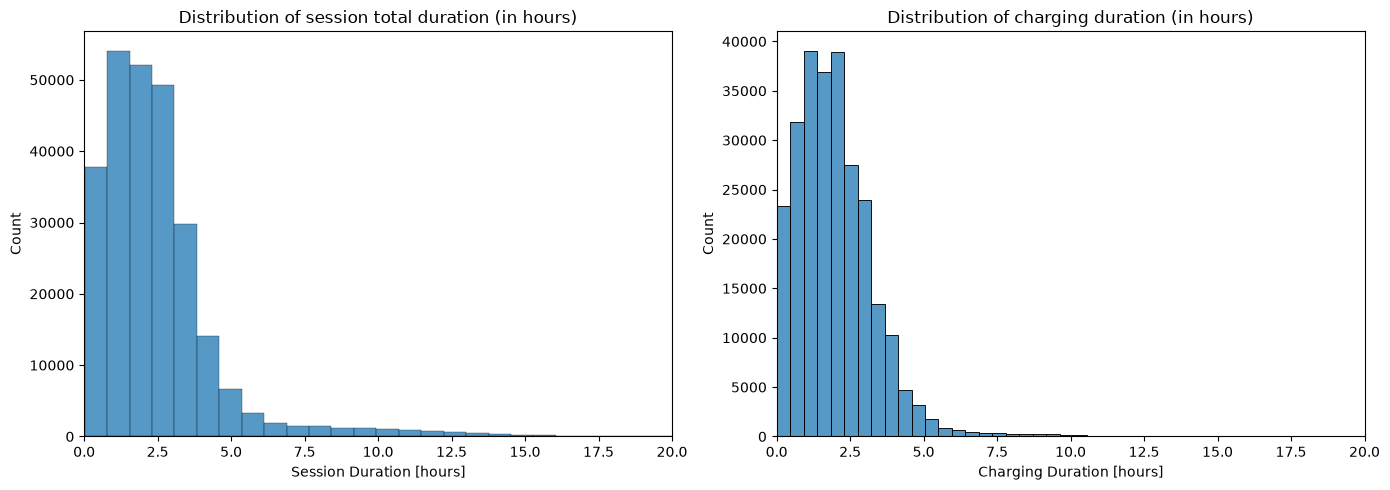

Charging time shorter by at least 15 min: 29.08%


In [182]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df, x="total_duration_hours",
    bins=150, ax=axes[0]
)
axes[0].set_title("Distribution of session total duration (in hours)")
axes[0].set_xlabel("Session Duration [hours]")

sns.histplot(
    data=df, x="charging_duration_hours",
    bins=50, ax=axes[1]
)
axes[1].set_title("Distribution of charging duration (in hours)")
axes[1].set_xlabel("Charging Duration [hours]")
axes[0].set_xlim(0, 20)
axes[1].set_xlim(0, 20)
plt.tight_layout()
plt.show()

valid = df[["charging_duration_hours", "total_duration_hours"]].dropna()
diff = valid["total_duration_hours"] - valid["charging_duration_hours"]
percent = (diff >= 15 / 60).mean() * 100

print(f"Charging time shorter by at least 15 min: {percent:.2f}%")

Charging time is shorter than total duration with most total durations being around 2.5h long and charhing times <2.5h. For 29% of events charging time was at least 15min shorter than the whole session.

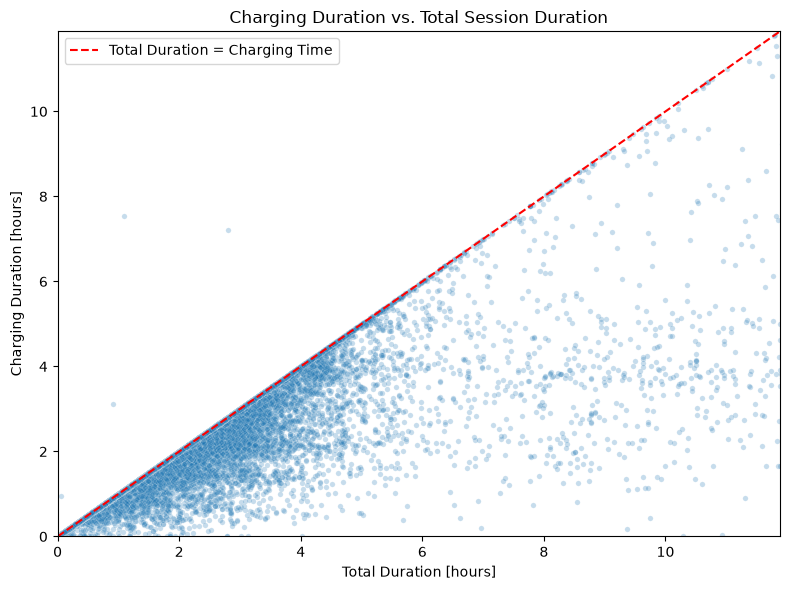

In [183]:
sample = df[
    ["total_duration_hours", "charging_duration_hours"]
].dropna()

if len(sample) > 20000:
    sample = sample.sample(20000, random_state=42)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=sample,
    x="total_duration_hours",
    y="charging_duration_hours",
    alpha=0.25,
    s=15
)

limit = sample[["total_duration_hours", "charging_duration_hours"]].quantile(0.99).max()
plt.plot([0, limit], [0, limit], "--", color="red",
         label="Total Duration = Charging Time")

plt.xlim(0, limit)
plt.ylim(0, limit)
plt.xlabel("Total Duration [hours]")
plt.ylabel("Charging Duration [hours]")
plt.title("Charging Duration vs. Total Session Duration")
plt.legend()
plt.tight_layout()
plt.show()

In [184]:
print("Average total duration (hours):", df["total_duration_hours"].mean())
print("Average charging duration (hours):", df["charging_duration_hours"].mean())

Average total duration (hours): 2.4868208222774753
Average charging duration (hours): 1.9991236446534615


Average charging duration is about 2h. Meaning that idle time = 30 min is equal to 1/4 of the charging time.

### Stations analysis 

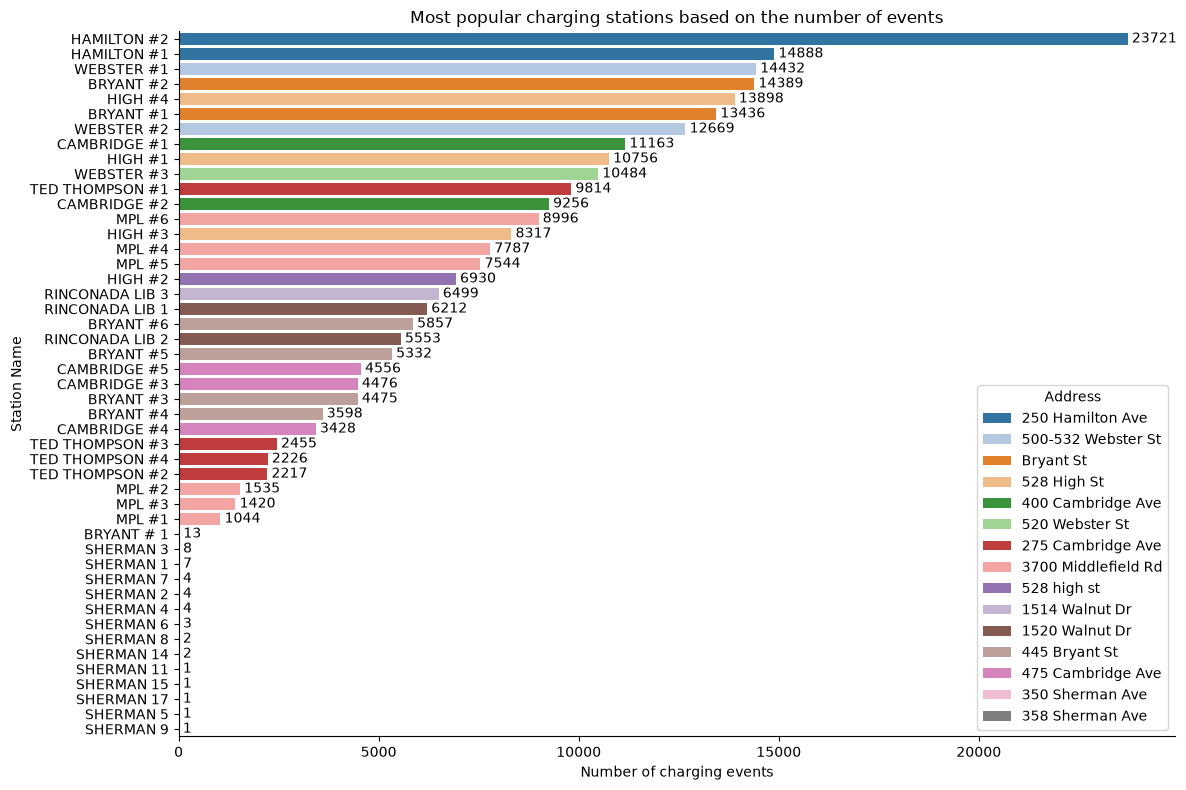

In [185]:
# plot most 'popular' stations based on the number of charging events
station_counts = (
    df.groupby("Station Name")
      .agg(
          n_events=("Station Name", "size"),
          address=("Address 1", "first")
      )
      .sort_values("n_events", ascending=False)
      .reset_index()
)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=station_counts,
    x="n_events",
    y="Station Name",
    hue="address",
    dodge=False,
    palette=sns.color_palette("tab20", n_colors=15)
)
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

labels = [label.get_text().replace("PALO ALTO CA / ", "") 
          for label in ax.get_yticklabels()]

ax.set_yticklabels(labels)
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xlabel("Number of charging events")
plt.ylabel("Station Name")
plt.title("Most popular charging stations based on the number of events")
plt.legend(title="Address")
plt.tight_layout()
plt.show()


2 Stations on Hamilton Ave had the most overall charging events. Sherman stations were almost completely unused.

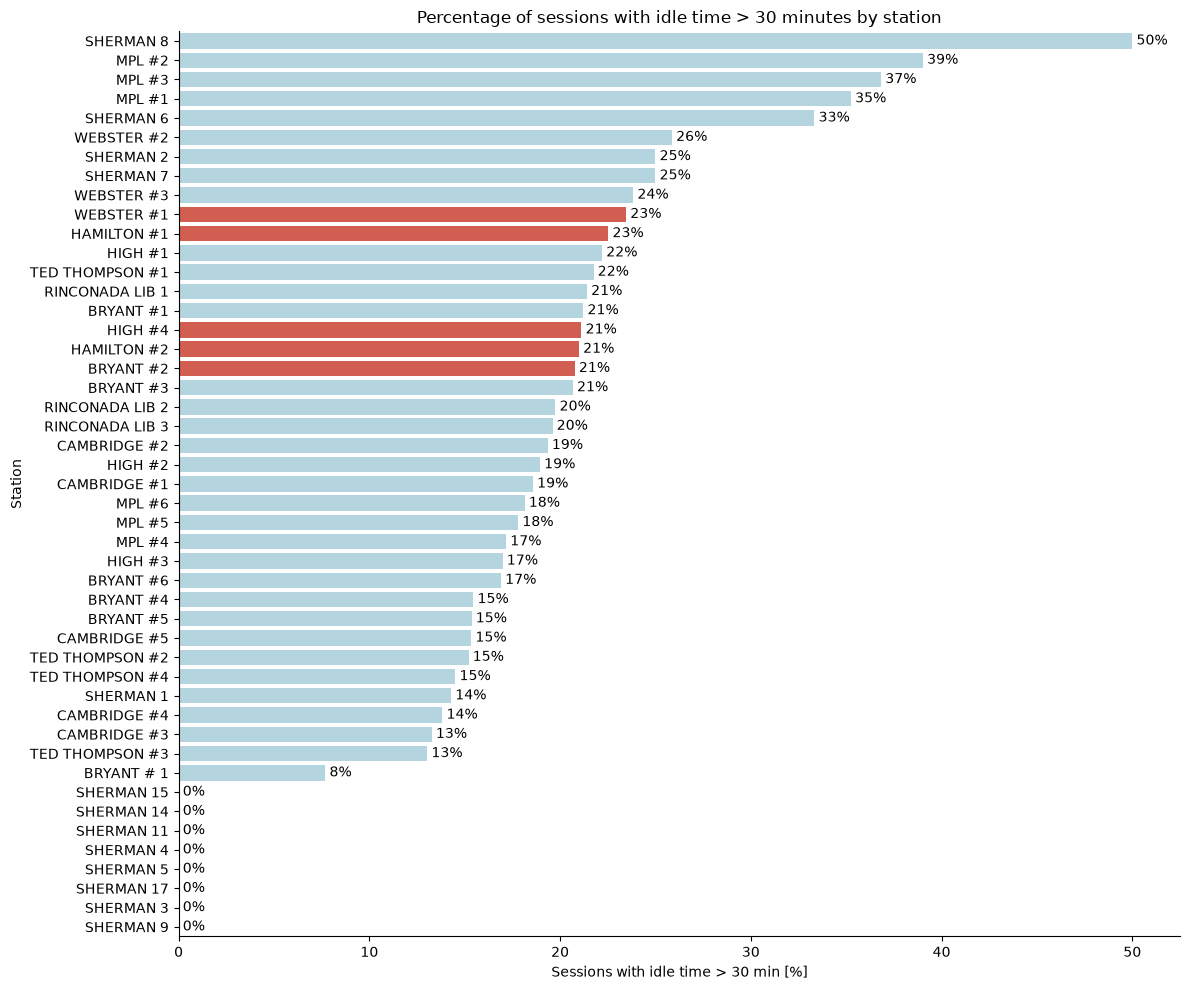

In [186]:
# plot the percentage of sessions with idle time greater than 20 minutes for each station
# highlighted most popular stations in red
idle_pct = (
    df.groupby("Station Name")["idle_hours"]
    .agg(
        total="count",
        above_30min=lambda x: (x > 30 / 60).sum()
    )
    .assign(percent=lambda x: 100 * x["above_30min"] / x["total"])
    .sort_values("percent", ascending=False)
)

highlight_stations = [
    "PALO ALTO CA / HAMILTON #1",
    "PALO ALTO CA / WEBSTER #1",
    "PALO ALTO CA / HAMILTON #2",
    "PALO ALTO CA / BRYANT #2",
    "PALO ALTO CA / HIGH #4",
]

plot_data = idle_pct.reset_index()
plot_data["color"] = plot_data["Station Name"].apply(
    lambda x: "Highlight" if x in highlight_stations else "Other"
)

palette = {"Highlight": "#e74c3c", "Other": "lightblue"}

fig, ax = plt.subplots(figsize=(12, 10))

sns.barplot(
    data=plot_data,
    x="percent",
    y="Station Name",
    hue="color",
    palette=palette,
    dodge=False,
    legend=False,
    ax=ax
)
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", padding=3)
labels = [
    label.get_text().replace("PALO ALTO CA / ", "")
    for label in ax.get_yticklabels()
]
ax.set_yticklabels(labels)

ax.set_xlabel("Sessions with idle time > 30 min [%]")
ax.set_ylabel("Station")
ax.set_title("Percentage of sessions with idle time > 30 minutes by station")

sns.despine()
plt.tight_layout()
plt.show()

Least popular stations have a high percentage (but this is also due to a low number of events). The top 5 most popular stations have the % of events with idle time>30 min at around 20%, which is quite high.

### Port type analysis

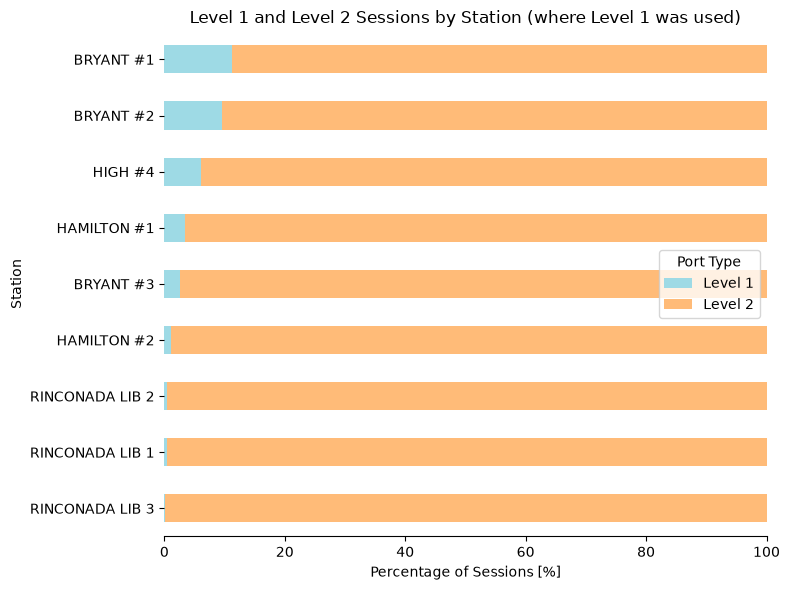

In [187]:
# Stations where at least one Level 1 session occurred
stations_level1 = df.loc[
    df["Port Type"] == "Level 1", "Station Name"
].unique()

df_levels = df[
    df["Station Name"].isin(stations_level1)
    & df["Port Type"].isin(["Level 1", "Level 2"])
].copy()

level_pct = pd.crosstab(
    df_levels["Station Name"],
    df_levels["Port Type"],
    normalize="index"
) * 100

level_pct = level_pct.reindex(
    columns=["Level 1", "Level 2"], fill_value=0
).sort_values("Level 2", ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))

level_pct.plot(
    kind="barh",
    stacked=True,
    color=["#9edae5", "#ffbb78"],
    ax=ax
)

labels = [
    label.get_text().replace("PALO ALTO CA / ", "")
    for label in ax.get_yticklabels()
]
ax.set_yticklabels(labels)

ax.set_xlabel("Percentage of Sessions [%]")
ax.set_ylabel("Station")
ax.set_title("Level 1 and Level 2 Sessions by Station (where Level 1 was used)")
ax.legend(title="Port Type")
ax.set_xlim(0, 100)


sns.despine(ax=ax)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

Port Type = Level 1 was only used at 10 stations, and the % of events with Level1 are less than 20% on each station. Level 1 is avalibale at both of the most popular Hamilton stations

### Durations deeper dive

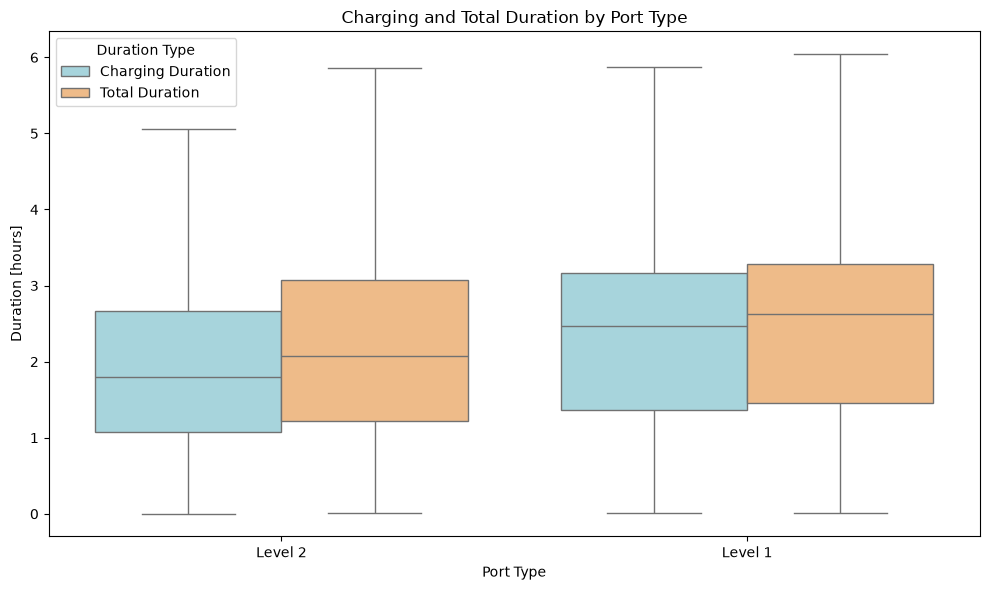

In [188]:
# plot the distribution of charging/total duration for Level 1 and Level 2 sessions
df_plot = df_levels.melt(
    id_vars="Port Type",
    value_vars=["charging_duration_hours", "total_duration_hours"],
    var_name="Duration Type",
    value_name="Duration [hours]"
)

df_plot["Duration Type"] = df_plot["Duration Type"].map({
    "charging_duration_hours": "Charging Duration",
    "total_duration_hours": "Total Duration"
})

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_plot,
    x="Port Type",
    y="Duration [hours]",
    hue="Duration Type",
    showfliers=False,
    palette=["#9edae5", "#ffbb78"]
)

plt.xlabel("Port Type")
plt.ylabel("Duration [hours]")
plt.title("Charging and Total Duration by Port Type")
plt.legend(title="Duration Type")
plt.tight_layout()
plt.show()

Level 1 is a slower port type; the differences in total duration vs charging duration are bigger for Level2 charging events.

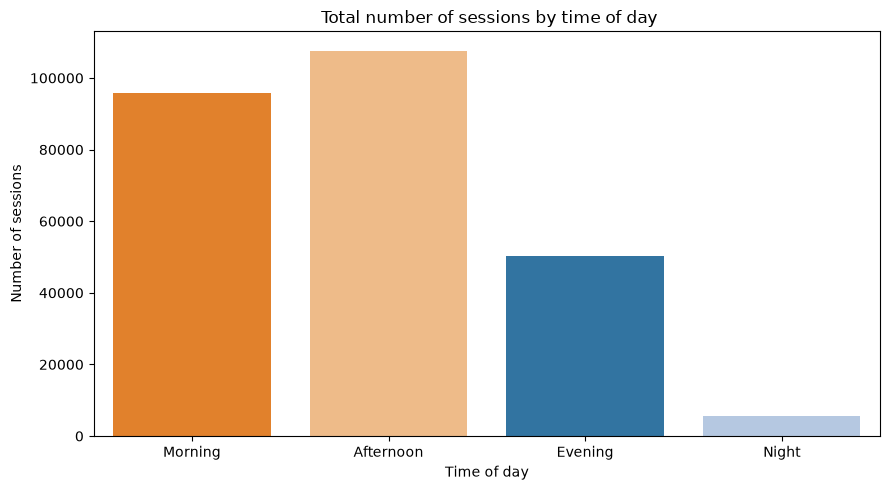

In [189]:
order = [ "Morning", "Afternoon", "Evening", "Night"]

plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="time_of_day",
    order=order,
    hue="time_of_day",
    palette="tab20",
    legend=False
)

plt.xlabel("Time of day")
plt.ylabel("Number of sessions")
plt.title(" Total number of sessions by time of day")
plt.tight_layout()
plt.show()

The highest charging traffic happens in the morning and afternoon

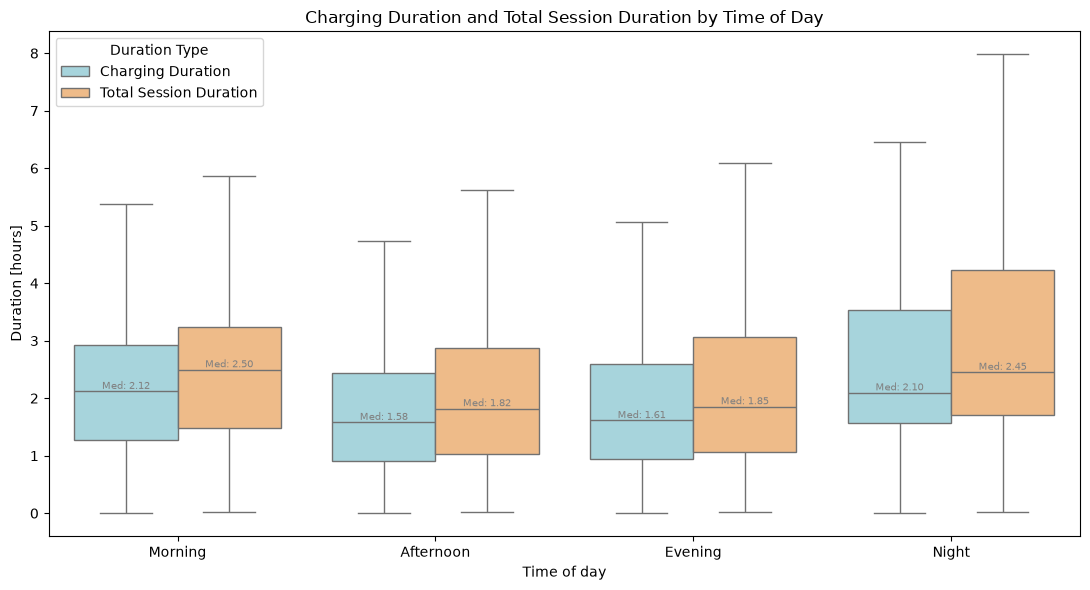

In [196]:
# plot the distribution of charging / total duration for each time of day
df_plot = df.melt(
    id_vars="time_of_day",
    value_vars=["charging_duration_hours", "total_duration_hours"],
    var_name="Duration Type",
    value_name="Duration [hours]"
)

df_plot["Duration Type"] = df_plot["Duration Type"].map({
    "charging_duration_hours": "Charging Duration",
    "total_duration_hours": "Total Session Duration"
})

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df_plot,
    x="time_of_day",
    y="Duration [hours]",
    order=order,
    hue="Duration Type",
    palette=["#9edae5", "#ffbb78"],
    showfliers=False
)

plt.xlabel("Time of day")
plt.ylabel("Duration [hours]")
plt.title("Charging Duration and Total Session Duration by Time of Day")
plt.legend(title="Duration Type")
# Add Q1, median and Q3 labels
stats = (
    df_plot.groupby(["time_of_day", "Duration Type"])["Duration [hours]"]
    .quantile([0.25, 0.5, 0.75])
    .unstack()
)
n_hue = 2
offsets = [-0.2, 0.2]

for i, tod in enumerate(order):
    for j, duration_type in enumerate(["Charging Duration", "Total Session Duration"]):
        if (tod, duration_type) not in stats.index:
            continue

        q1, median, q3 = stats.loc[(tod, duration_type)].values
        x = i + offsets[j]

        ax = plt.gca()
        ax.text(x, median, f"Med: {median:.2f}",
                ha="center", va="bottom", fontsize=7, color='gray')
plt.tight_layout()
plt.show()

The highest charging and total times are observed in the morning and night. At night there are some outliers reaching up to 8h of total duration (the spread is also the greatest at night). The biggest difference in Medians between charging and total time is 0.38 (Mornings).

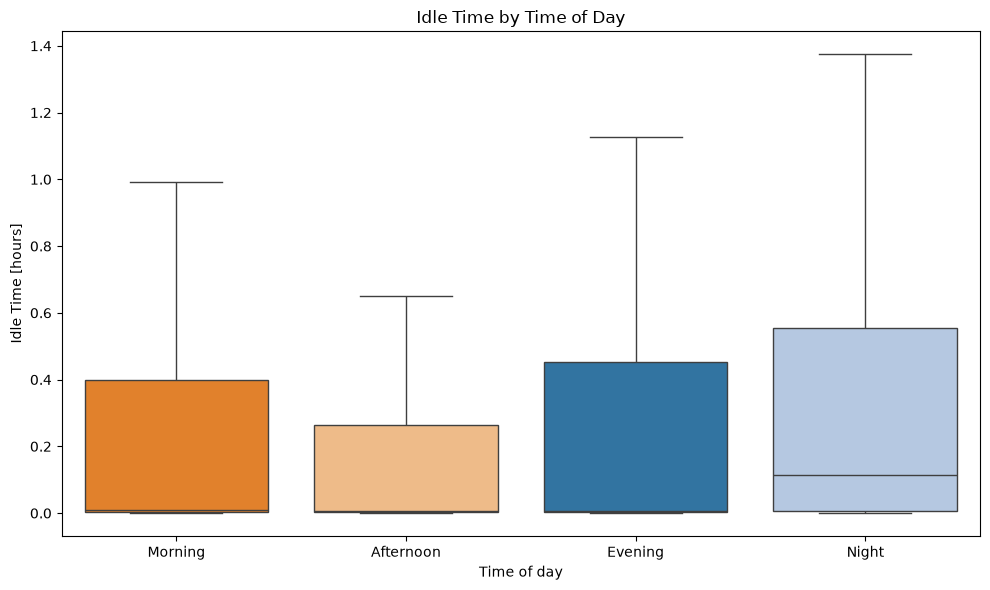

In [197]:
# Idle time analysis by time of day
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df[df["idle_hours"] >= 0],
    x="time_of_day",
    y="idle_hours",
    order=order,
    hue="time_of_day",
    palette="tab20",
    showfliers=False,
    legend=False
)

plt.xlabel("Time of day")
plt.ylabel("Idle Time [hours]")
plt.title("Idle Time by Time of Day")
plt.tight_layout()
plt.show()

At night idle times are the highest (up to 1.4h) with median areound 0.1h